## Lecture 1

### Understanding your customer type

![Image](customerpersonalitytypes.png)

It is quiet important to have the right customers than just having customers. Various studdies support that it is cheaper to keep loyal customer than acquiring new customers. It is one of the biggests problem most business face today. The first step in keeping a customer is understanding Them. But before we get to the example.

![Image](quotes.jpg)

#### Example

Suppose out of our 100 customers 30 customers only buy from us during festival or only during offers.
Should we or should we not focus on these customers,
the answer is yes and no.

We should focus on these customers mainly during festival instead of wasting resources with a wishful thinking that they may convert into regular customer( of course effort must be put towards but if every effort fails is better to focus on regular customers).

Choosing those customers who regulary choose us is the way to develop a business.

> **Problem Statement**
>
> Considering the varying personalities and behaviours of our customers.
>* Build a model which will segement our customers.
>* Help the business to better understand its customers
>* Makes it easier for the bussiness to
>    * Modify products according to the specific needs, behaviors and concerns of different types of customers.

## Step 0) Load the data

*Data read from `../data/` (no upload needed outside Colab).*

### Step 1) Know your data

#### Step 1.1) Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# import io
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('../data/marketing_campaign.csv')#, sep='\t')

How big is the data?

In [3]:
df.shape

(2240, 29)

In [4]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


![Image](data_description.png)

Attributes

People

    ID: Customer's unique identifier
    Year_Birth: Customer's birth year
    Education: Customer's education level
    Marital_Status: Customer's marital status
    Income: Customer's yearly household income
    Kidhome: Number of children in customer's household
    Teenhome: Number of teenagers in customer's household
    Dt_Customer: Date of customer's enrollment with the company
    Recency: Number of days since customer's last purchase
    Complain: 1 if the customer complained in the last 2 years, 0 otherwise

Products

    MntWines: Amount spent on wine in last 2 years
    MntFruits: Amount spent on fruits in last 2 years
    MntMeatProducts: Amount spent on meat in last 2 years
    MntFishProducts: Amount spent on fish in last 2 years
    MntSweetProducts: Amount spent on sweets in last 2 years
    MntGoldProds: Amount spent on gold in last 2 years

Promotion

    NumDealsPurchases: Number of purchases made with a discount
    AcceptedCmp1: 1 if customer accepted the offer in the 1st campaign, 0 otherwise
    AcceptedCmp2: 1 if customer accepted the offer in the 2nd campaign, 0 otherwise
    AcceptedCmp3: 1 if customer accepted the offer in the 3rd campaign, 0 otherwise
    AcceptedCmp4: 1 if customer accepted the offer in the 4th campaign, 0 otherwise
    AcceptedCmp5: 1 if customer accepted the offer in the 5th campaign, 0 otherwise
    Response: 1 if customer accepted the offer in the last campaign, 0 otherwise

Place

    NumWebPurchases: Number of purchases made through the company’s website
    NumCatalogPurchases: Number of purchases made using a catalogue
    NumStorePurchases: Number of purchases made directly in stores
    NumWebVisitsMonth: Number of visits to company’s website in the last month


-------------

**Step 1.2) Lets have a look at data type**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i



> **Notice that:**

>    * We have 3 object types- in which one is a datetime.
>    * Remaining we have integer type
>    * Can we drop the id column?
>          Yes, It is a unique identifier but for generalisation we need to remove it.



In [6]:
df.drop('ID',axis=1,inplace=True)

Now let's quickly look at the actual data

In [7]:
df.head()

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,...,7,0,0,0,0,0,0,3,11,1
1,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,...,5,0,0,0,0,0,0,3,11,0
2,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,...,4,0,0,0,0,0,0,3,11,0
3,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,...,6,0,0,0,0,0,0,3,11,0
4,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,...,5,0,0,0,0,0,0,3,11,0


We get a glimps here but all 28 columns do not fit in here.

So we will iterate on these columns and find the unique values and print them, however we do not want to print for columns that may have a million unique values. They may be continuous values. like **Income**

`len(df.Income.unique()) = 1975`

In [8]:
unique = [feature for feature in df.columns if len(df[feature].unique())>0 and len(df[feature].unique())<100]
for feature in unique:
    print("{} has {} unique values : {} {}".format(feature,len(df[feature].unique()),df[feature].unique(),"\n"))


Year_Birth has 59 unique values : [1957 1954 1965 1984 1981 1967 1971 1985 1974 1950 1983 1976 1959 1952
 1987 1946 1980 1949 1982 1979 1951 1969 1986 1989 1963 1970 1973 1943
 1975 1996 1968 1964 1977 1978 1955 1966 1988 1948 1958 1972 1960 1945
 1991 1962 1953 1961 1956 1992 1900 1893 1990 1947 1899 1993 1994 1941
 1944 1995 1940] 

Education has 5 unique values : ['Graduation' 'PhD' 'Master' 'Basic' '2n Cycle'] 

Marital_Status has 8 unique values : ['Single' 'Together' 'Married' 'Divorced' 'Widow' 'Alone' 'Absurd' 'YOLO'] 

Kidhome has 3 unique values : [0 1 2] 

Teenhome has 3 unique values : [0 1 2] 

NumDealsPurchases has 15 unique values : [ 3  2  1  5  4 15  7  0  6  9 12  8 10 13 11] 

NumWebPurchases has 15 unique values : [ 8  1  2  5  6  7  4  3 11  0 27 10  9 23 25] 

NumCatalogPurchases has 14 unique values : [10  1  2  0  3  4  6 28  9  5  8  7 11 22] 

NumStorePurchases has 14 unique values : [ 4  2 10  6  7  0  3  8  5 12  9 13 11  1] 

NumWebVisitsMonth has 16 unique

**Step 1.3) Check variables (numerical values)**

In [9]:
numerical_features = [feature for feature in df.columns if df[feature].dtype != "O"]
print("we have {} numerical features out of {}".format(len(numerical_features),len(df.columns)))

we have 25 numerical features out of 28


    Any varible/feature that has a limited number of unique values in it is called as discrete variables,in our case we will select 25 features


## Discrete features

In [10]:
discrete_features = [feature for feature in numerical_features if len(df[feature].unique())<25]
print("we have {} discrete features out of {} total features".format(len(discrete_features),len(df.columns)))

we have 16 discrete features out of 28 total features


In [11]:
df[discrete_features].head()

,Kidhome,Teenhome,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,0,0,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,1,1,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,0,0,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,1,0,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,1,0,5,5,3,6,5,0,0,0,0,0,0,3,11,0


### Step 2) Data cleaning

**Step 2.1) Data standardisation**

Let us standardise by converting all the string columns into lowercase for easier analysis.

In [12]:
df.columns = df.columns.str.lower()

**Step 2.2) Missing values**

It is important to fill in missing values.
There are multiple ways of filling in. Each has it's pros and cons. Some popular ways are

1. Drop the data rows that has missing values.

2. Impute using
    1. Mean values.
    2. Median values
    3. Most frequent
    4. Zero or constanct values
    5. Nearest neighbours
 etc...

In [13]:
total = df.isnull().sum().sort_values(ascending=False)
percent = (df.isnull().sum()/ df.isnull().count()*100)
missing = pd.concat([total,percent],axis =1,keys=['total','percent'])
missing.head()

,total,percent
income,24,1.071429
year_birth,0,0.000000
numwebpurchases,0,0.000000
z_revenue,0,0.000000
z_costcontact,0,0.000000


We have missing values in income and it's only 24. Compared to the size of our data set which is 2240. The missing values is only 0.01%. Thus if we drop this it would not make any difference.
However this is mostly not true in real world dataset

In [14]:
df = df.dropna()
print("we have {} missing values".format(df.isnull().sum().sum()))

we have 0 missing values


In [15]:
# demo data in df_demo so it does not overwrite the campaign df
import numpy as np
import pandas as pd

# Sample dirty dataset
data = {
    "Name": [" Alice ", "Bob", "CHARLIE", "Bob", "David"],
    "Age": [25, np.nan, 30, np.nan, 120],  # Missing values + outlier (120)
    "Salary": ["$50,000", "$60,000", np.nan, "$60,000", "$75,000"],

}

df_demo = pd.DataFrame(data)

# 1. Deduplication
# Removes exact duplicate rows without deleting missing data
df_demo = df_demo.drop_duplicates()

# 2. String Cleaning (Trimming whitespace & standardizing case)
df_demo["Name"] = df_demo["Name"].str.strip().str.capitalize()

# 3. Value Parsing & Type Casting
# Remove special characters ($ and ,) and convert text to float
df_demo["Salary"] = df_demo["Salary"].str.replace(r"[$,]", "", regex=True)
df_demo["Salary"] = pd.to_numeric(df_demo["Salary"])

# 4. Imputation (Replacing NaNs instead of dropping)
# Fill missing numeric values with summary statistics (median/mean)
df_demo["Salary"] = df_demo["Salary"].fillna(df_demo["Salary"].median())

# Interpolate missing sequential values
df_demo["Age"] = df_demo["Age"].interpolate(method="linear")

# 5. Outlier & Boundary Capping
# Restrict values to a valid range (e.g., capping max age at 80)
df_demo["Age"] = df_demo["Age"].clip(lower=18, upper=80)



print(df_demo)

      Name   Age   Salary
0    Alice  25.0  50000.0
1      Bob  27.5  60000.0
2  Charlie  30.0  60000.0
4    David  80.0  75000.0


**Step 2.3) Data Manipulation**

Creating new data column

It was noticable that we had 2 columns for children.
One was kids and other one was teen. Also there were multiple different types of purchases

* We will combine to have one feature called kids
* Similarly we will combine all purchases into one feature
* We will combine weather a customer accepted our offer or not

In [16]:
discrete_features = [x.lower() for x in discrete_features]

 **Univariate analysis**

In [17]:
# Filter discrete_features to only include columns that actually exist in df
valid_discrete_features = [col for col in discrete_features if col in df.columns]
fig, ax = plt.subplots(4, 4, figsize=(20, 15))

for variable, subplot in zip(valid_discrete_features, ax.flatten()):
    sns.countplot(x=df[variable], ax=subplot, palette="winter")


Index(['year_birth', 'education', 'marital_status', 'income', 'kidhome',
       'teenhome', 'dt_customer', 'recency', 'mntwines', 'mntfruits',
       'mntmeatproducts', 'mntfishproducts', 'mntsweetproducts',
       'mntgoldprods', 'numdealspurchases', 'numwebpurchases',
       'numcatalogpurchases', 'numstorepurchases', 'numwebvisitsmonth',
       'acceptedcmp3', 'acceptedcmp4', 'acceptedcmp5', 'acceptedcmp1',
       'acceptedcmp2', 'complain', 'z_costcontact', 'z_revenue', 'response'],
      dtype='object')

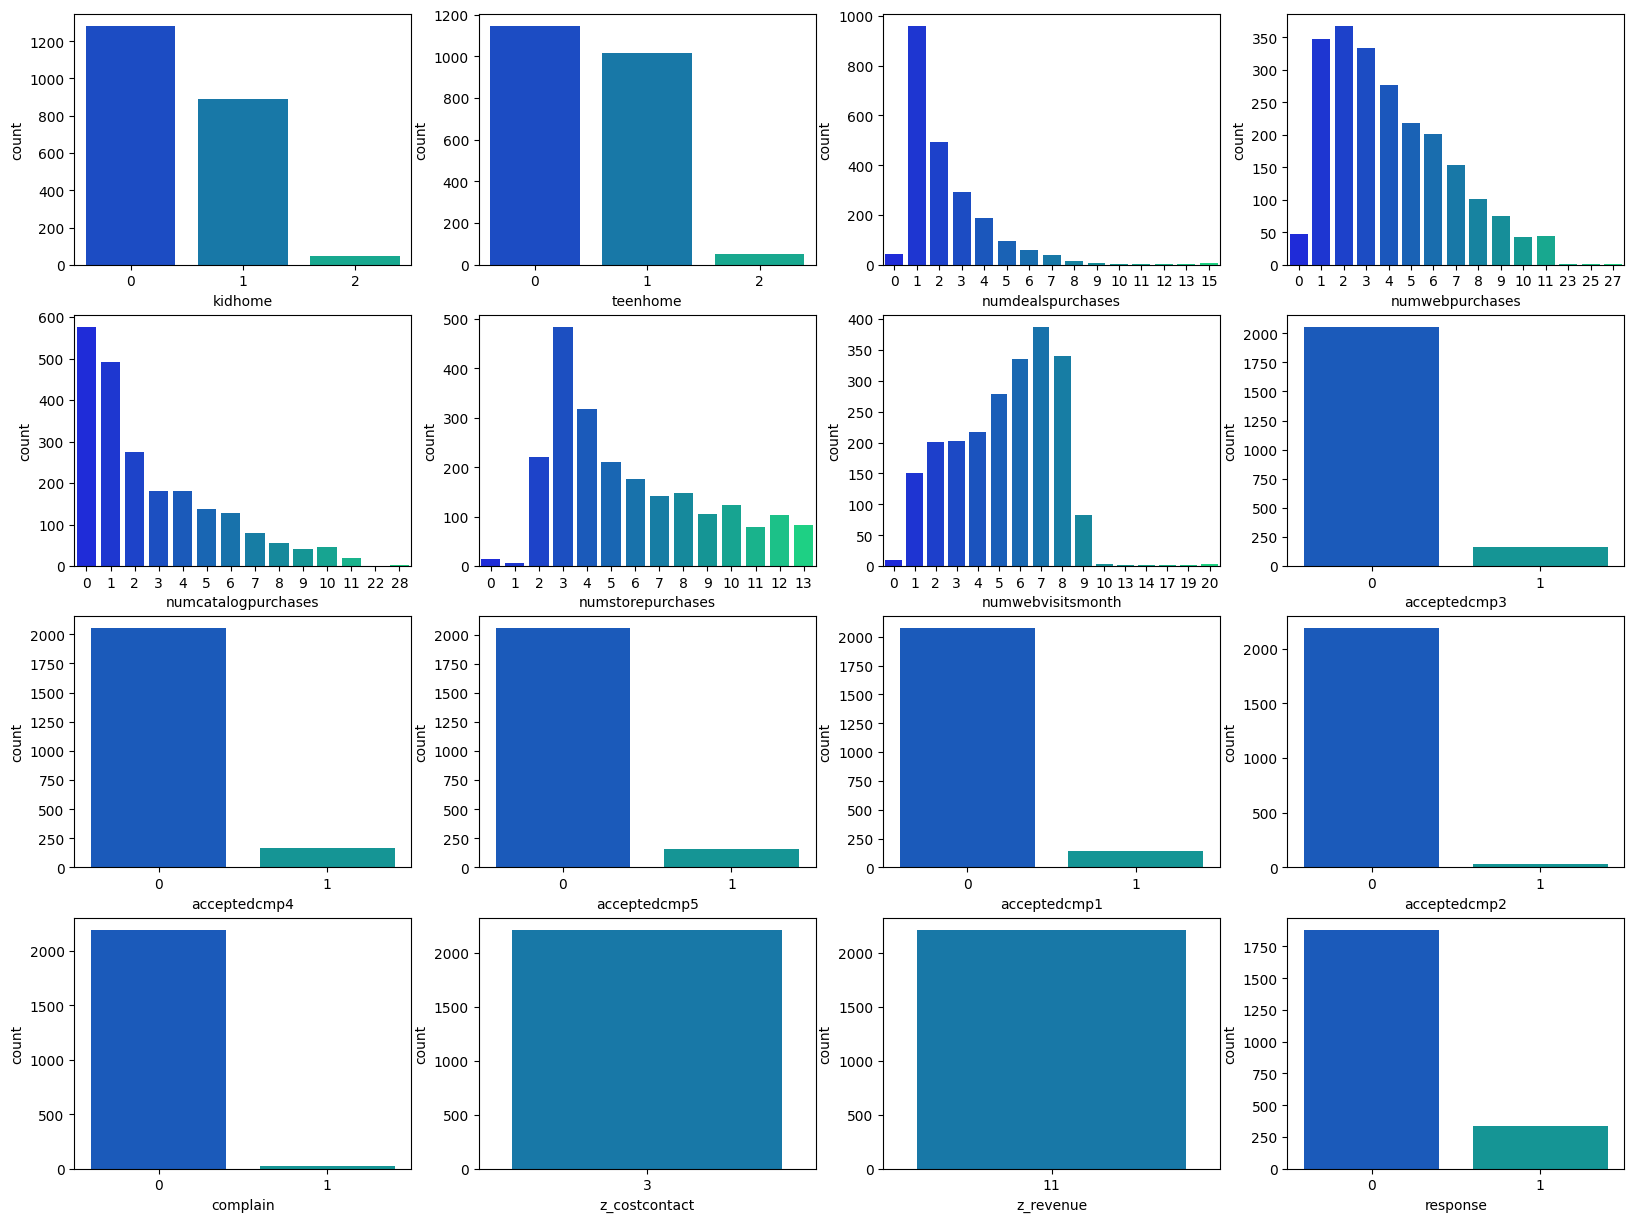

In [18]:
df.columns



**Inferences:**

   > * We can distinguish between parents and non-parents
   > * Most people purchased atleast one product via web.
   > * Most customers buy few items online,which is understandable since the data is only till 2014
   > * Most people don not use the catalog as the reference.
   > * Most people bought via a store
   > * Coming to campaign there is not much of a difference in each campaign,so we can also drop them or combine them
   > * Majority did not have any complains
   > * Vast majority did not respond to the campaign.



In [19]:
# this will combine both the kids into a single columns kids
df['total_kids'] = df['kidhome']+ df['teenhome']

In [20]:
df['total_kids']

0       0
1       2
2       0
3       1
4       1
       ..
2235    1
2236    3
2237    0
2238    1
2239    2
Name: total_kids, Length: 2216, dtype: int64

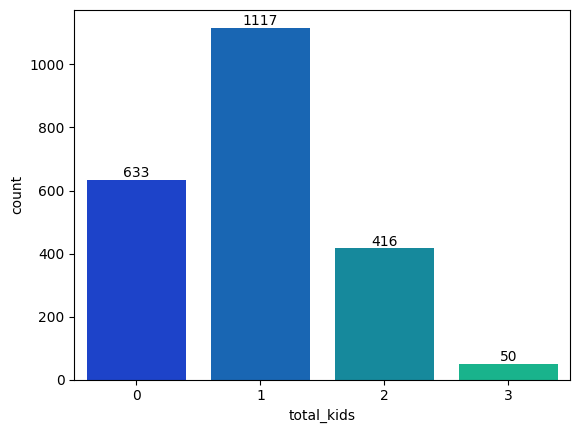

In [21]:
ax = sns.countplot(data=df, x='total_kids', palette='winter')

# Loop through every container to label each bar
for container in ax.containers:
    ax.bar_label(container)

* When we combine both teen and kid into one we can see that most people have atleast one child

##  total_Accepted and total_purchase

-----
Let us create a new feature for total_Accepted and total_purchase since as we can see there is not a huge difference between each so we are better off having a single feature rather than multiple

In [22]:
df['total_accep'] = df['acceptedcmp1'] + df['acceptedcmp2']+df['acceptedcmp3'] + df['acceptedcmp4']
+df['acceptedcmp5'] + df['response']

df['total_purchase'] = df['numdealspurchases']+df['numwebpurchases']+df['numcatalogpurchases']+df['numstorepurchases']


**Correction** (Charlotte):
In the cell above, the second line starts with `+`, so Python reads it as a separate expression: `acceptedcmp5` and `response` are not added to `total_accep`. The parentheses below keep the whole sum in one expression.

In [23]:
# total_accep: sum of all the accepted campaigns and the last response
df['total_accep'] = (df['acceptedcmp1'] + df['acceptedcmp2'] + df['acceptedcmp3']
                     + df['acceptedcmp4'] + df['acceptedcmp5'] + df['response'])

Let us drop all the irrelevant features, the features we have combined to a new feature

In [24]:
columns_dropped = ['kidhome','teenhome','numdealspurchases','numwebpurchases','numcatalogpurchases',
         'numstorepurchases','numwebvisitsmonth','acceptedcmp3',
         'acceptedcmp4','acceptedcmp5','acceptedcmp1','acceptedcmp2',
         'complain','z_costcontact','z_revenue','response']

In [25]:
df.drop(columns_dropped,axis=1,inplace=True)

In [26]:
df.head()

,year_birth,education,marital_status,income,dt_customer,recency,mntwines,mntfruits,mntmeatproducts,mntfishproducts,mntsweetproducts,mntgoldprods,total_kids,total_accep,total_purchase
0,1957,Graduation,Single,58138.0,2012-09-04,58,635,88,546,172,88,88,0,1,25
1,1954,Graduation,Single,46344.0,2014-03-08,38,11,1,6,2,1,6,2,0,6
2,1965,Graduation,Together,71613.0,2013-08-21,26,426,49,127,111,21,42,0,0,21
3,1984,Graduation,Together,26646.0,2014-02-10,26,11,4,20,10,3,5,1,0,8
4,1981,PhD,Married,58293.0,2014-01-19,94,173,43,118,46,27,15,1,0,19


-------

**Continuous variables**

In contrast to discrete variables features that do not have limited number of values in it is called continiuos variables

In [27]:
continuos_features = [feature for feature in numerical_features if feature not in discrete_features]
print("we have {} continuos features out of {} total features".format(len(continuos_features),len(df.columns)))

we have 25 continuos features out of 15 total features


In [28]:
continuos_features = [x.lower() for x in continuos_features]

Dropping the numerical columns we dropped earlier

In [29]:
continuos_features = [x for x in continuos_features if x not in columns_dropped]

In [30]:
continuos_features

['year_birth',
 'income',
 'recency',
 'mntwines',
 'mntfruits',
 'mntmeatproducts',
 'mntfishproducts',
 'mntsweetproducts',
 'mntgoldprods']

In [31]:
df.columns

Index(['year_birth', 'education', 'marital_status', 'income', 'dt_customer',
       'recency', 'mntwines', 'mntfruits', 'mntmeatproducts',
       'mntfishproducts', 'mntsweetproducts', 'mntgoldprods', 'total_kids',
       'total_accep', 'total_purchase'],
      dtype='object')

In [32]:
df[continuos_features].head()

,year_birth,income,recency,mntwines,mntfruits,mntmeatproducts,mntfishproducts,mntsweetproducts,mntgoldprods
0,1957,58138.0,58,635,88,546,172,88,88
1,1954,46344.0,38,11,1,6,2,1,6
2,1965,71613.0,26,426,49,127,111,21,42
3,1984,26646.0,26,11,4,20,10,3,5
4,1981,58293.0,94,173,43,118,46,27,15


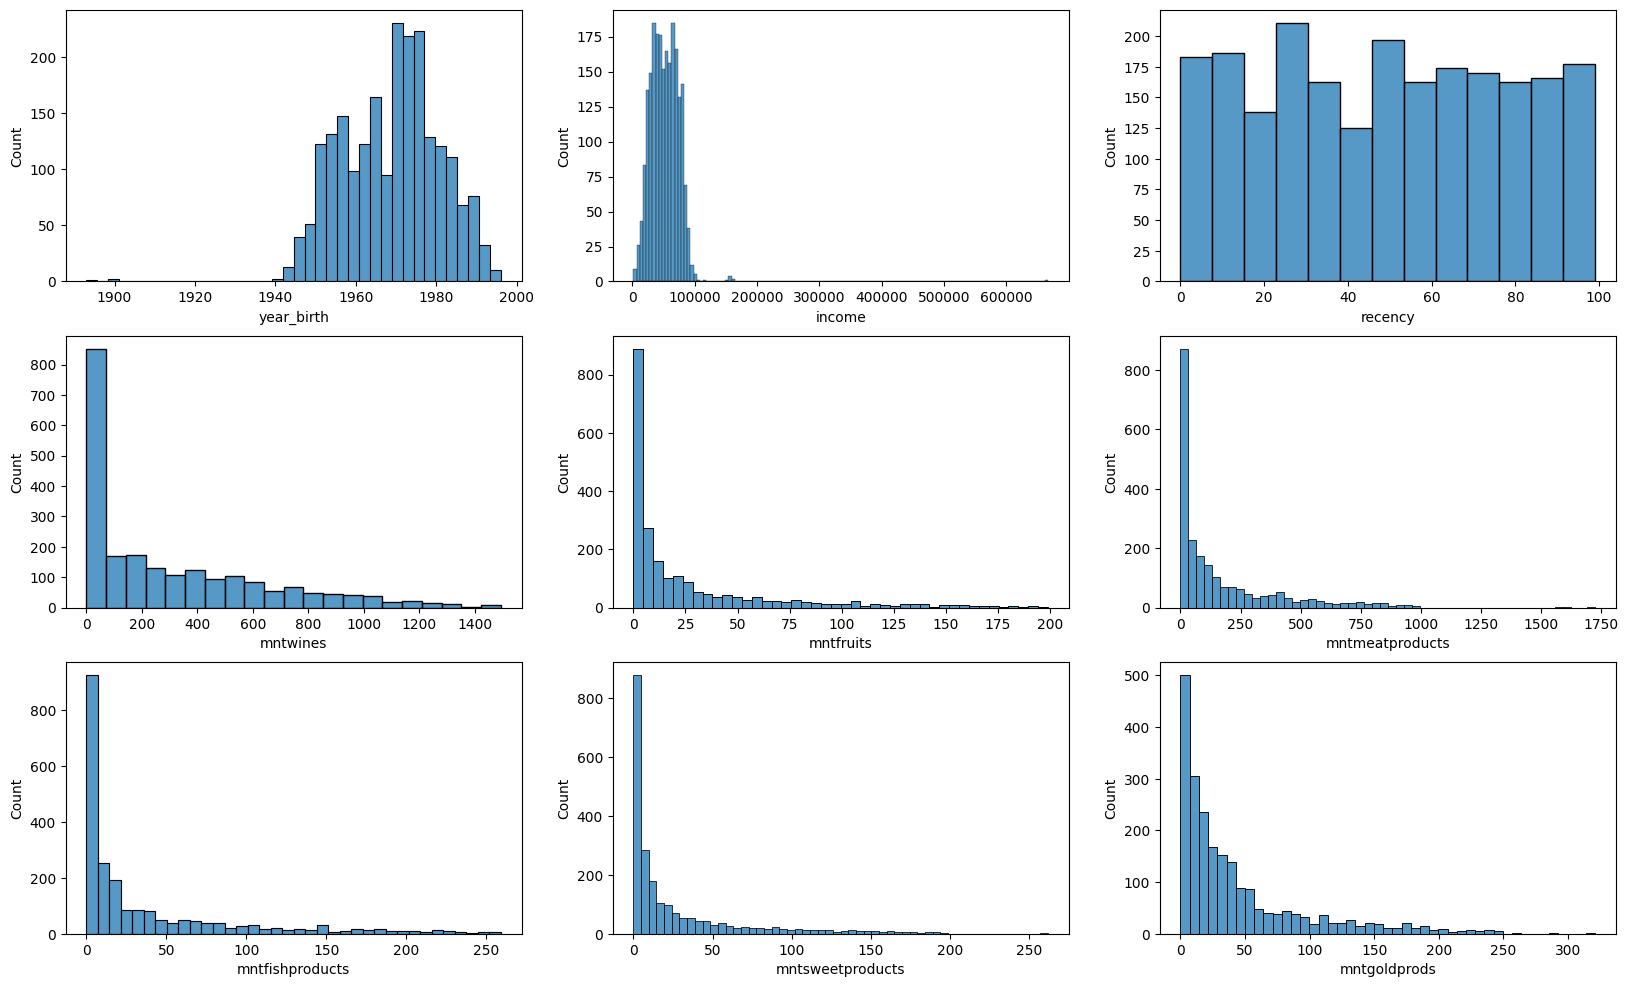

In [33]:
fig,ax = plt.subplots(3,3,figsize=(20,12))
for variable, subplot in zip(continuos_features,ax.flatten()):
    sns.histplot(df[variable],ax=subplot)



**Inferences:**

   > * Year and income has outliers in it
   > * 30 days seems to be the longest time since the customers last purchase
   > * Instead of having so many columns on amount spent we can combine all the features into one feature which will have the total spending of a customer
   > * we can also create a new age feature which will be easier to remove outliers



In [34]:
df['age'] = 2026 - df['year_birth']
df['total_amount__spent']= df['mntwines'] + df['mntfruits'] +df['mntmeatproducts']
+df["mntfishproducts"] +df['mntsweetproducts']+df['mntgoldprods']

0       348
1         9
2       174
3        18
4        88
       ... 
2235    407
2236      8
2237     68
2238    171
2239     24
Length: 2216, dtype: int64

**Corrections** (Charlotte):
* `age`: the data stops in 2014 (newest `dt_customer`), so the age is computed in 2014, not 2026.
* `total_amount__spent`: same issue as `total_accep`, the line starting with `+` is not added, so only wines, fruits and meat were counted.

In [35]:
# age in 2014, the last year of the data
df['age'] = 2014 - df['year_birth']

# total_amount__spent: sum of the 6 product categories
df['total_amount__spent'] = (df['mntwines'] + df['mntfruits'] + df['mntmeatproducts']
                             + df['mntfishproducts'] + df['mntsweetproducts'] + df['mntgoldprods'])

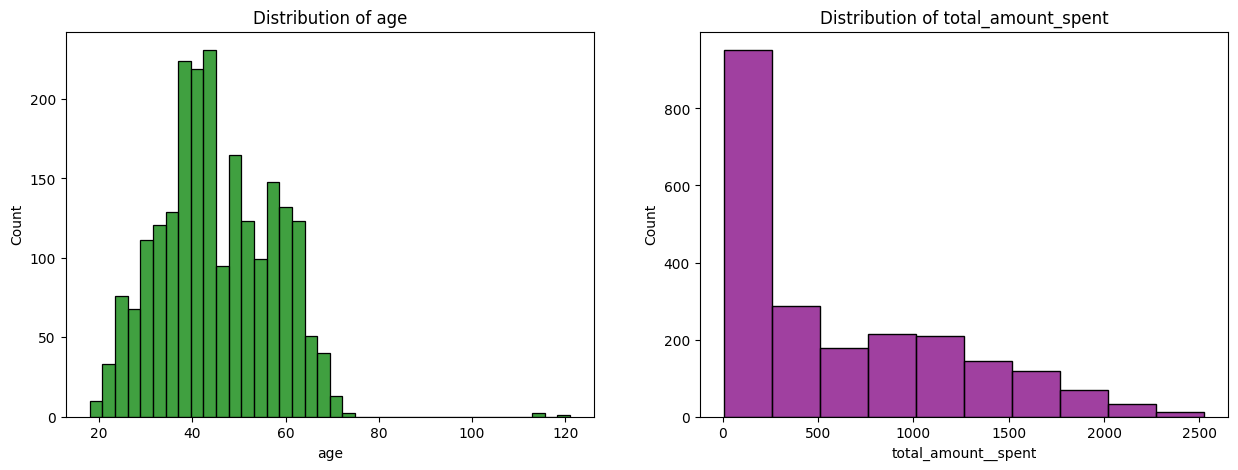

In [36]:
plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
sns.histplot(df['age'],color='green')
plt.title('Distribution of age')

plt.subplot(1,2,2)
sns.histplot(df['total_amount__spent'],color='purple',bins=10)
plt.title('Distribution of total_amount_spent');

* Let us drop all the unnecessary features

In [37]:
df.drop(['mntwines','mntfruits','mntmeatproducts','mntfishproducts','mntsweetproducts','mntgoldprods'],axis=1,inplace=True)

In [38]:
df.head()

,year_birth,education,marital_status,income,dt_customer,recency,total_kids,total_accep,total_purchase,age,total_amount__spent
0,1957,Graduation,Single,58138.0,2012-09-04,58,0,1,25,57,1617
1,1954,Graduation,Single,46344.0,2014-03-08,38,2,0,6,60,27
2,1965,Graduation,Together,71613.0,2013-08-21,26,0,0,21,49,776
3,1984,Graduation,Together,26646.0,2014-02-10,26,1,0,8,30,53
4,1981,PhD,Married,58293.0,2014-01-19,94,1,0,19,33,422


**Categorical variables**

In [39]:
categorical_features = [feature for feature in df.columns if df[feature].dtype == "O"]
print("we have {} continuos features out of {} features".format(len(categorical_features),len(df.columns)))

we have 3 continuos features out of 11 features


In [40]:
df[categorical_features].head()

,education,marital_status,dt_customer
0,Graduation,Single,2012-09-04
1,Graduation,Single,2014-03-08
2,Graduation,Together,2013-08-21
3,Graduation,Together,2014-02-10
4,PhD,Married,2014-01-19


* As we can see dt_customer is a datetime variable we will convert it into datetime

In [41]:
df["dt_customer"] = pd.to_datetime(df["dt_customer"]).dt.date
print("The newest date is:",max(df["dt_customer"]))
print("The oldest date is:",min(df["dt_customer"]))

The newest date is: 2014-06-29
The oldest date is: 2012-07-30


In [42]:
df.dt_customer.dtype

dtype('O')

* Let us create a function which will show how many days has it been since the customer started shopping from us

In [43]:
from datetime import date
days = []
d1 = max(df['dt_customer'])
for i in df['dt_customer']:
    delta = d1 - i
    days.append(delta.days)
df["total_days"] = days
df["total_days"] = pd.to_numeric(df["total_days"], errors="coerce")

## Removing repetition for education and marital status

* when we were checking the unique values in the column we saw that in education and married most of the data was repeated let us see it once again

In [44]:
print("education      :",df.education.unique())
print("marital_status :",df.marital_status.unique())

education      : ['Graduation' 'PhD' 'Master' 'Basic' '2n Cycle']
marital_status : ['Single' 'Together' 'Married' 'Divorced' 'Widow' 'Alone' 'Absurd' 'YOLO']


* Let us create new features for both education and marital status

In [45]:
df['marital_status'] = df['marital_status'].replace({"Together":"Married", "Absurd":"Single",
                                                     "Widow":"Single", "YOLO":"Single",
                                                     "Divorced":"Single", "Alone":"Single",})

df['education'] = df['education'].replace({"Basic":"Undergraduate","2n Cycle":"Undergraduate",
                                           "Graduation":"Graduate", "Master":"Postgraduate",
                                           "PhD":"Postgraduate"})

Text(0.5, 1.0, 'Distribution of Education')

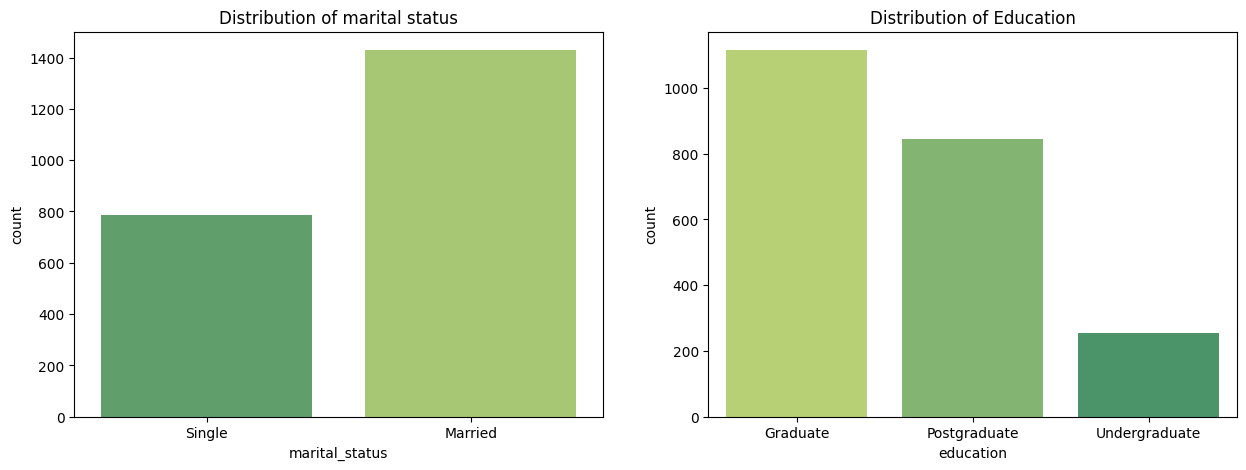

In [46]:
plt.figure(figsize=(15, 5))

# Vertical plot for marital status
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='marital_status', palette='summer')
plt.title('Distribution of marital status')

# Vertical plot for education
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='education', palette='summer_r')
plt.title('Distribution of Education')


**Inferences:**

   > * Most people are married in our dataset.
   > * Most peoples are graduates in our dataset

## Family column

* Let us create a new column which will have the family members and if a person in a house is a parent. This may give us information about single parent.

Text(0.5, 1.0, 'Distribution of Is Parent')

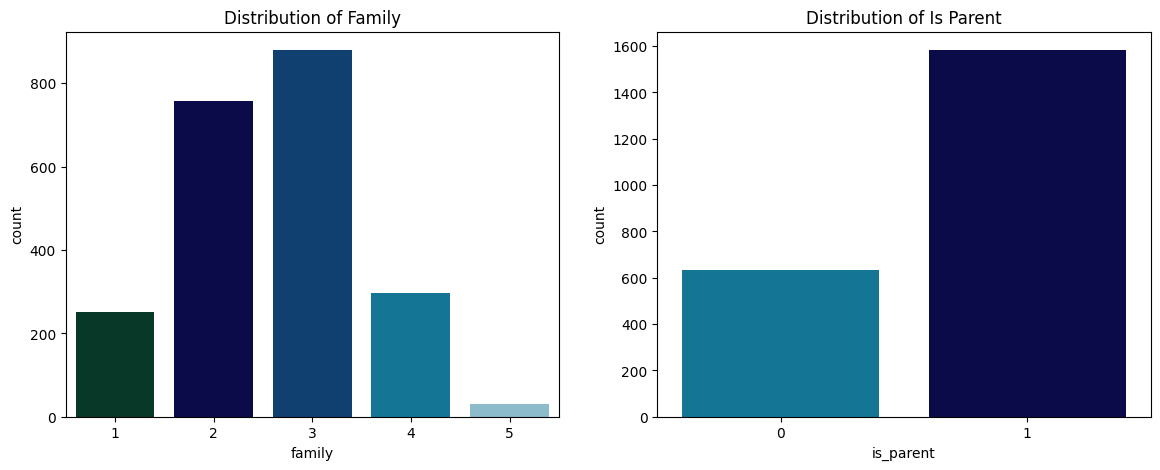

In [47]:
df['family'] = df['marital_status'].replace({'Single':1,"Married":2}) + df['total_kids']
# we will create a new column which will contain all the total members in an household

df['is_parent'] = np.where(df.total_kids>0,1,0)
# this feature will choose 1 if a family has a parent in it else 0

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='family', palette='ocean')
plt.title('Distribution of Family')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='is_parent', palette='ocean_r')
plt.title('Distribution of Is Parent')

**Inferences:**

   > * We can see most people in an household are a parent.
   > * Most family has atleast 2 and 3 members in it

* Let us clean data again to remove features we will not use again.

In [48]:
df.drop(['year_birth','dt_customer','recency',],axis=1,inplace=True)

In [49]:
df.head()

,education,marital_status,income,total_kids,total_accep,total_purchase,age,total_amount__spent,total_days,family,is_parent
0,Graduate,Single,58138.0,0,1,25,57,1617,663,1,0
1,Graduate,Single,46344.0,2,0,6,60,27,113,3,1
2,Graduate,Married,71613.0,0,0,21,49,776,312,2,0
3,Graduate,Married,26646.0,1,0,8,30,53,139,3,1
4,Postgraduate,Married,58293.0,1,0,19,33,422,161,3,1


-------

**Step 2.4) Outlier removal**

We initially observed that there were some outliers in age and income. It is important to remove these outliers as they will skew our modelling.

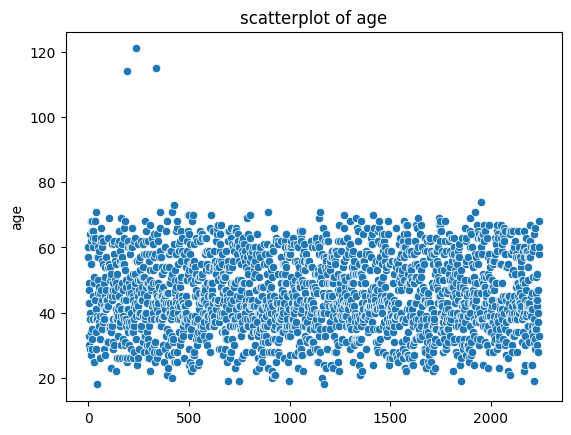

In [50]:
sns.scatterplot(data =df['age'])
plt.title('scatterplot of age');

In [51]:
df[df['age']>90]

,education,marital_status,income,total_kids,total_accep,total_purchase,age,total_amount__spent,total_days,family,is_parent
192,Undergraduate,Single,36640.0,1,0,6,114,65,276,2,1
239,Undergraduate,Single,60182.0,1,0,4,121,22,43,2,1
339,Postgraduate,Married,83532.0,0,1,15,115,1853,276,2,0


These are the rows where the age of the individual is greater than 90. We will drop these rows.

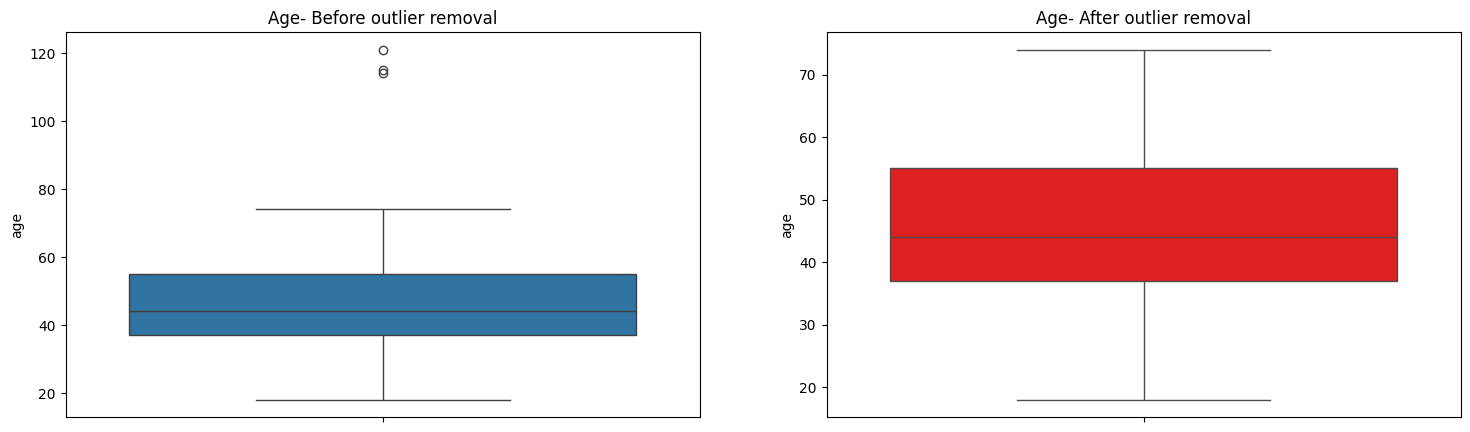

In [52]:
plt.figure(figsize=(18,5))
plt.subplot(1,2,1)
sns.boxplot(df['age'])
plt.title("Age- Before outlier removal");

df = df.drop(df[df['age']>90].index)  # to remove the outliers

plt.subplot(1,2,2)
sns.boxplot(df['age'],color='r')
plt.title('Age- After outlier removal');

## Income

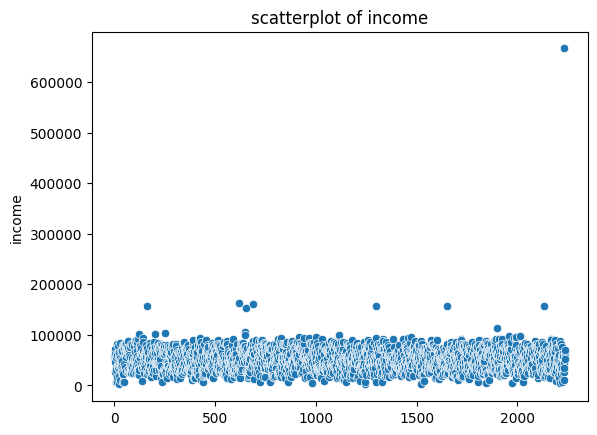

In [53]:
sns.scatterplot(data = df['income'])
plt.title('scatterplot of income');

We can remove data either data after 150000 or after 600000, we will go with 600000 and let some outliers be

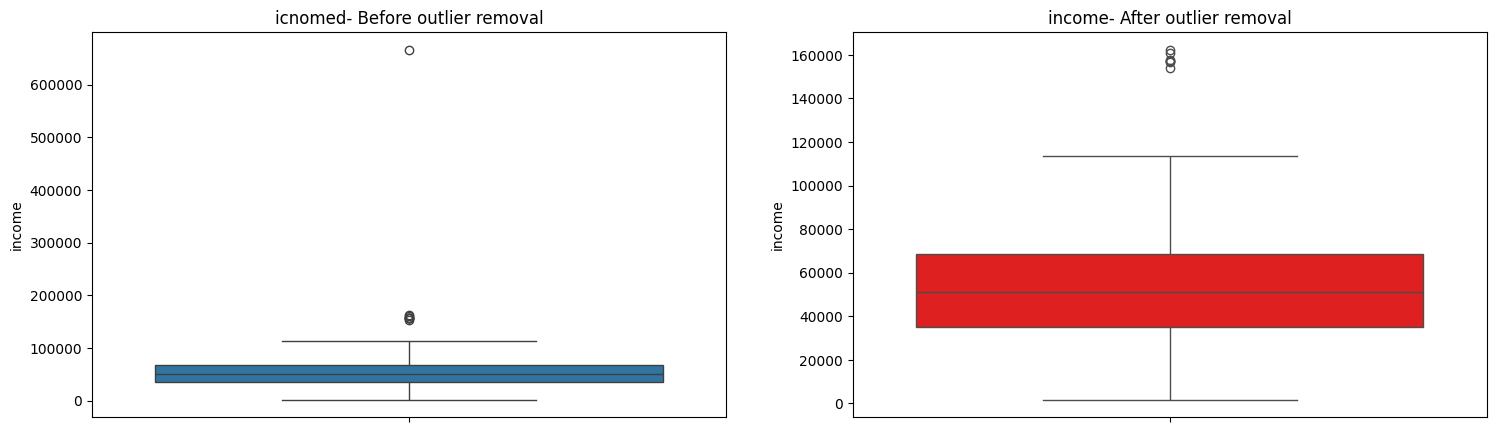

In [54]:
plt.figure(figsize=(18,5))
plt.subplot(1,2,1)
sns.boxplot(df['income'])
plt.title("icnomed- Before outlier removal");

df = df.drop(df[df['income']>600000].index)  # to remove the outliers

plt.subplot(1,2,2)
sns.boxplot(df['income'],color='r')
plt.title('income- After outlier removal');

**Step 2.5) Correlation**

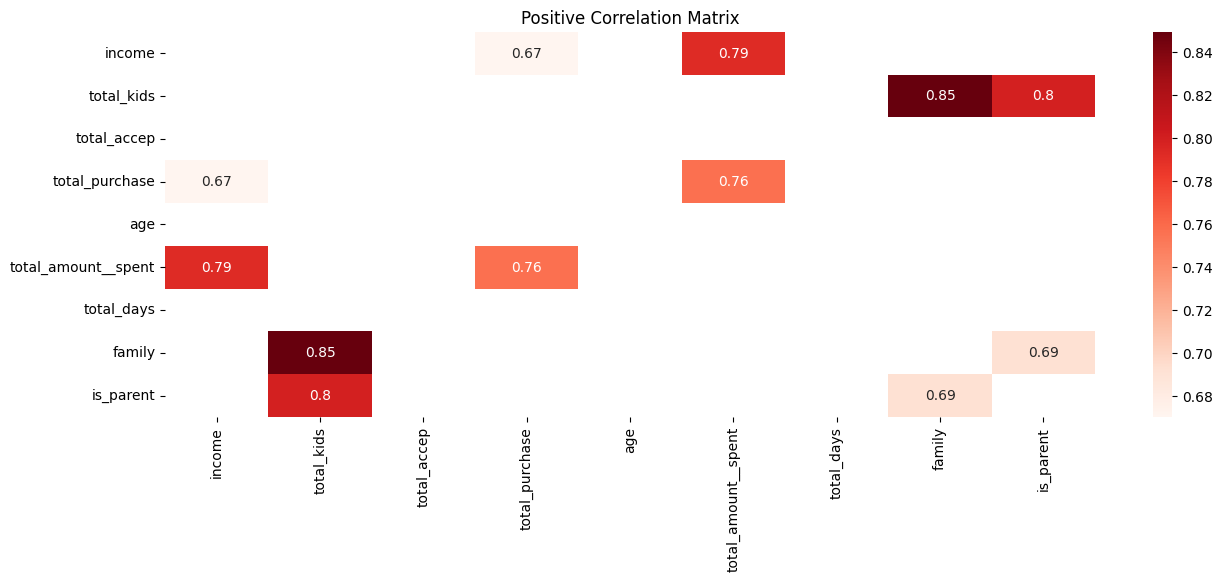

In [55]:
pos_corrmat = df.corr(numeric_only=True)

# Filter for values >= 0.5 and excluding 1.0 (self-correlation)
filtereddf = pos_corrmat[(pos_corrmat >= 0.5) & (pos_corrmat != 1.000)]

plt.figure(figsize=(15, 5))
sns.heatmap(filtereddf, annot=True, cmap="Reds")
plt.title('Positive Correlation Matrix')
plt.show()

### Step 3) Data preparation

In [56]:
object_feat = [feature for feature in df.columns if df[feature].dtype == "O"]
df[object_feat].head()

,education,marital_status
0,Graduate,Single
1,Graduate,Single
2,Graduate,Married
3,Graduate,Married
4,Postgraduate,Married


**Why standardize?:**

   > * Standardizing makes the mean 0 and variance as 1 which in turn makes all the data consistent throughout.
   > * Standardized data takes less computational power than non-standardized one.
   > * It reduces the bias if present in the dataset.
   > > * It is not mandatory that we must always scale the data but since we are working on clustering where distance between the datapoints are considered it is better to standardize the data.

## One Hot Encoding

In [57]:
df.head()

,education,marital_status,income,total_kids,total_accep,total_purchase,age,total_amount__spent,total_days,family,is_parent
0,Graduate,Single,58138.0,0,1,25,57,1617,663,1,0
1,Graduate,Single,46344.0,2,0,6,60,27,113,3,1
2,Graduate,Married,71613.0,0,0,21,49,776,312,2,0
3,Graduate,Married,26646.0,1,0,8,30,53,139,3,1
4,Postgraduate,Married,58293.0,1,0,19,33,422,161,3,1


In [58]:
df['education'].unique()

array(['Graduate', 'Postgraduate', 'Undergraduate'], dtype=object)

In [59]:
df['marital_status'].unique()

array(['Single', 'Married'], dtype=object)

In [60]:
# Convert object columns into binary 0/1 indicator columns
df = pd.get_dummies(df, columns=object_feat, drop_first=False, dtype=int)

In [61]:
df.head()

,income,total_kids,total_accep,total_purchase,age,total_amount__spent,total_days,family,is_parent,education_Graduate,education_Postgraduate,education_Undergraduate,marital_status_Married,marital_status_Single
0,58138.0,0,1,25,57,1617,663,1,0,1,0,0,0,1
1,46344.0,2,0,6,60,27,113,3,1,1,0,0,0,1
2,71613.0,0,0,21,49,776,312,2,0,1,0,0,1,0
3,26646.0,1,0,8,30,53,139,3,1,1,0,0,1,0
4,58293.0,1,0,19,33,422,161,3,1,0,1,0,1,0


In [62]:
# from sklearn.preprocessing import LabelEncoder
# le = LabelEncoder()

# for i in object_feat:
#     df[i] = df[[i]].apply(le.fit_transform)

In [63]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df2 = scaler.fit_transform(df)

In [64]:
df2 = pd.DataFrame(df2,columns = df.columns)
# converting the transformed data into dataframe
df2.head()

,income,total_kids,total_accep,total_purchase,age,total_amount__spent,total_days,family,is_parent,education_Graduate,education_Postgraduate,education_Undergraduate,marital_status_Married,marital_status_Single
0,0.287105,-1.264598,0.617244,1.317945,1.018352,1.676245,1.527721,-1.758359,-1.581139,0.991895,-0.786220,-0.358569,-1.349603,1.349603
1,-0.260882,1.404572,-0.502808,-1.159273,1.274785,-0.963297,-1.189011,0.449070,0.632456,0.991895,-0.786220,-0.358569,-1.349603,1.349603
2,0.913196,-1.264598,-0.502808,0.796425,0.334530,0.280110,-0.206048,-0.654644,-1.581139,0.991895,-0.786220,-0.358569,0.740959,-0.740959
3,-1.176114,0.069987,-0.502808,-0.898513,-1.289547,-0.920135,-1.060584,0.449070,0.632456,0.991895,-0.786220,-0.358569,0.740959,-0.740959
4,0.294307,0.069987,-0.502808,0.535666,-1.033114,-0.307562,-0.951915,0.449070,0.632456,-1.008171,1.271909,-0.358569,0.740959,-0.740959


### Step 4) Modelling

### K-Means Clustering
**What is K-Means clusting?**
k-means clustering is an unsupervised ml algorithm and steps involved are:
* Randomly select k points(also called centroids)
* Assign the values to its nearest centroid
* Calculate the distance between points and centroid
* Iterate this process till there is no change in any of the clusters

![Image](data3d.gif)

In [65]:
scaled_df= df2.copy()

**Elbow method is one of the methods that is used to calculate the k-value, I.e number of optimal clusters**

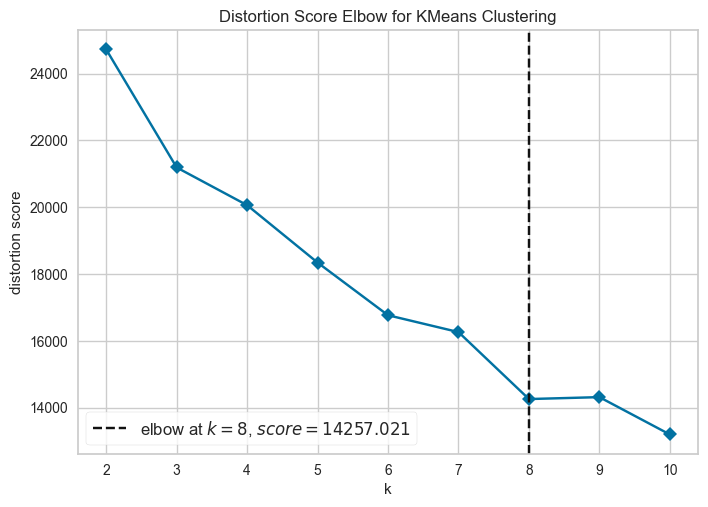

In [66]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
model = KMeans()
visualizer = KElbowVisualizer(model, k=(2,11),timings = False)
visualizer.fit(scaled_df)
visualizer.show();

It is noticable that 3 is the optimum cluster. It is based on the Distortion score and time.
**Distortion score** in current context is defined as the sum of the squared distances between each observation vector and its dominating centroid.
Each step of the k-means algorithm refines the choices of centroids to reduce distortion.

-------

**Step 4.1) Train model**

In [67]:
kmeans = KMeans(n_clusters=6,init='k-means++',random_state=0)
pred_kmeans = kmeans.fit_predict(scaled_df)

**Note** (Charlotte):
The elbow method above suggests 3 clusters, but the model is trained with 6. To be consistent, `n_clusters` should be the k chosen with the elbow method.

* Let us create a new row in the original dataframe for analysing the predicted cluster and relation with other features

In [68]:
df['pred_kmeans'] = pred_kmeans+1
df.head()

,income,total_kids,total_accep,total_purchase,age,total_amount__spent,total_days,family,is_parent,education_Graduate,education_Postgraduate,education_Undergraduate,marital_status_Married,marital_status_Single,pred_kmeans
0,58138.0,0,1,25,57,1617,663,1,0,1,0,0,0,1,2
1,46344.0,2,0,6,60,27,113,3,1,1,0,0,0,1,3
2,71613.0,0,0,21,49,776,312,2,0,1,0,0,1,0,2
3,26646.0,1,0,8,30,53,139,3,1,1,0,0,1,0,4
4,58293.0,1,0,19,33,422,161,3,1,0,1,0,1,0,1


### Retransform the one-hot-encoded columns to the original form

In [69]:
# 1. Define dummy column groups
edu_cols = [
    'education_Graduate',
    'education_Postgraduate',
    'education_Undergraduate',
]
marital_cols = ['marital_status_Married', 'marital_status_Single']

# 2. Extract original category names
df['education'] = df[edu_cols].idxmax(axis=1).str.replace('education_', '')
df['marital_status'] = (
    df[marital_cols].idxmax(axis=1).str.replace('marital_status_', '')
)

# 3. Drop the dummy columns
df = df.drop(columns=edu_cols + marital_cols)

### Step 5) Analysis

In [70]:
personal = df[['education','marital_status','total_kids','total_accep','family','is_parent']]

We will now plot different features with respect to the predicted cluster

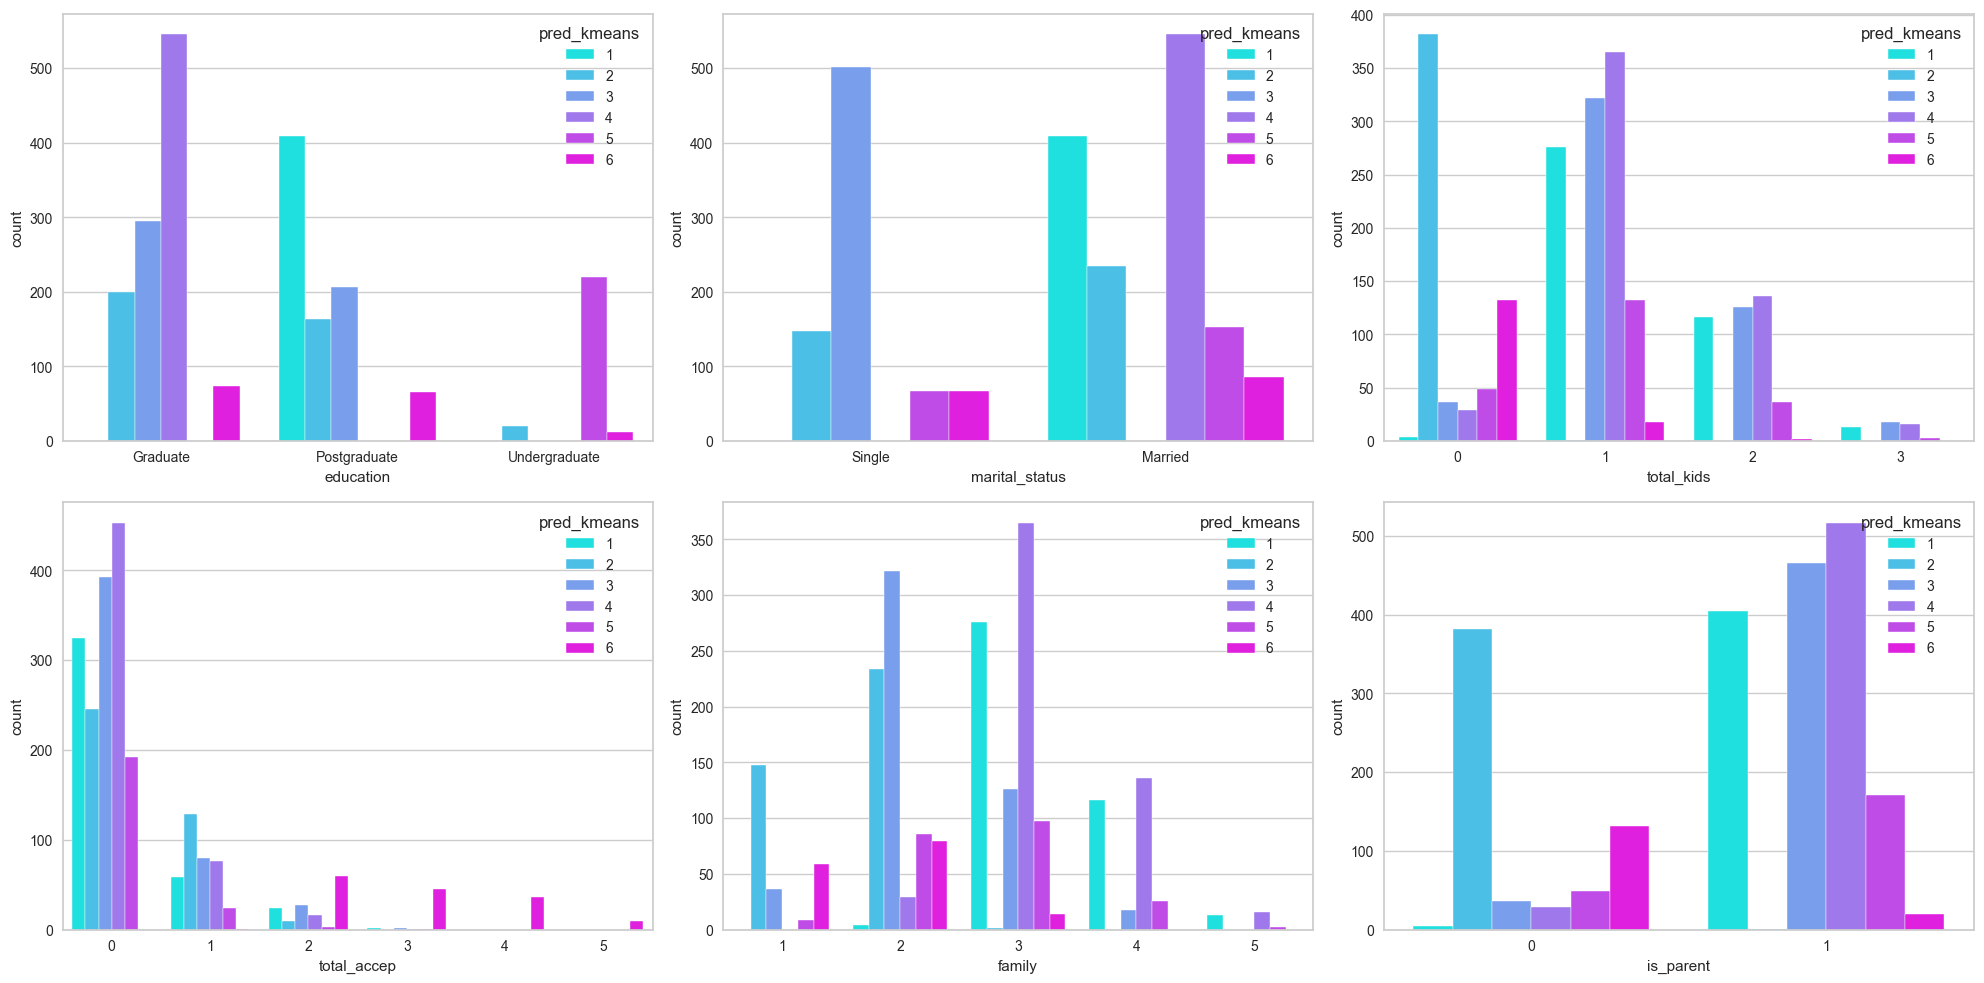

In [71]:
fig, ax = plt.subplots(2, 3, figsize=(20, 10))
sns.set_style('darkgrid')

for variable, subplot in zip(personal, ax.flatten()):
    sns.countplot(
        data=df,
        x=variable,
        hue='pred_kmeans',
        ax=subplot,
        palette='cool'
    )

plt.tight_layout()
plt.show()

In [72]:
other = df[['income','total_purchase','age','total_amount__spent','total_days']]

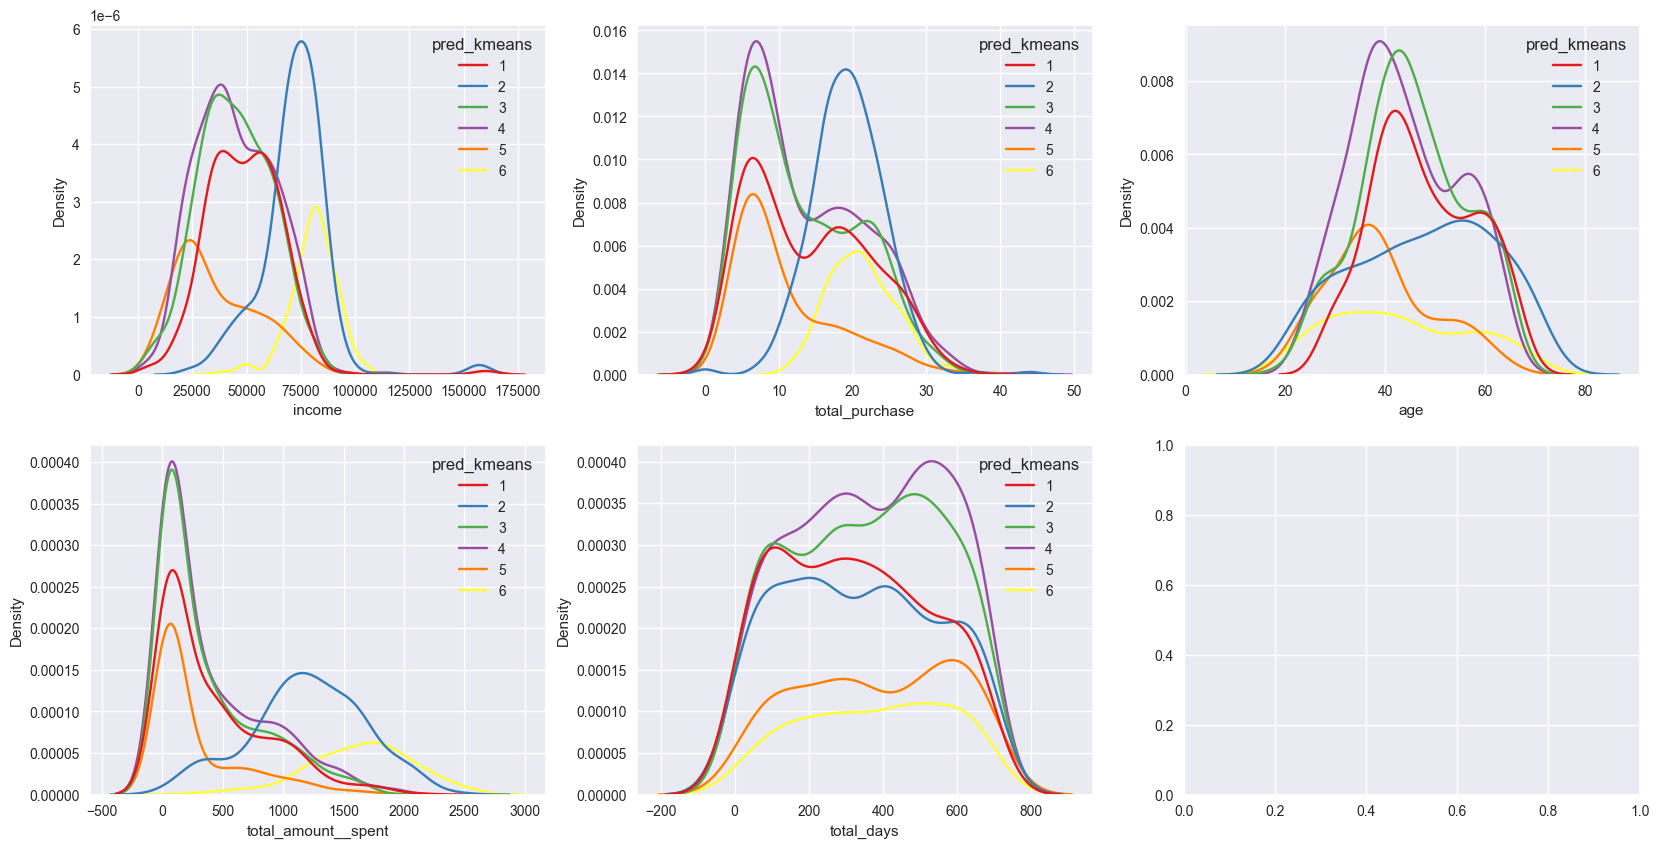

In [73]:
fig,ax = plt.subplots(2,3,figsize=(20,10))
sns.set_style('darkgrid')
for variable, subplot in zip(other,ax.flatten()):
    sns.kdeplot(data= df,x=variable,hue='pred_kmeans',ax=subplot,palette='Set1')